# Практическая работа № 4. Регрессионная модель

**Выполнил:** Айдар Нурбекович

**Цель:** предсказать месячный доход клиентов с помощью линейной регрессии и оценить качество модели.

	Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

	Загрузка Spotify Dataset

In [2]:
paths = [
    Path("../PR1/dataset.csv"),
    Path("PR1/dataset.csv")
]

dataset_path = next((p for p in paths if p.is_file()), None)

if dataset_path is None:
    raise FileNotFoundError("Не найден Spotify Dataset")

df = pd.read_csv(dataset_path)

print("Размер:", df.shape)
display(df.head())

Размер: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Выбор признаков и целевой переменной

In [3]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]

target = "popularity"

data = df[features + [target]].copy()
data = data.dropna(subset=[target])

X = data[features]
y = data[target]

print("Признаки:", X.shape)
print("Цель:", y.shape)

Признаки: (114000, 10)
Цель: (114000,)


Разделение данных на Train и Test

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (91200, 10)
Test: (22800, 10)


Обучение линейной регрессии

In [5]:
def make_model(columns):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])

baseline = make_model(features)

baseline.fit(X_train[features], y_train)

baseline_pred = baseline.predict(X_test[features])

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

baseline_metrics = evaluate(y_test, baseline_pred)

print("Базовая модель:")
print(baseline_metrics)

Базовая модель:
{'MAE': 18.354561606410677, 'RMSE': np.float64(21.98648282374415), 'R2': 0.020417119715080978}


	Анализ корреляций

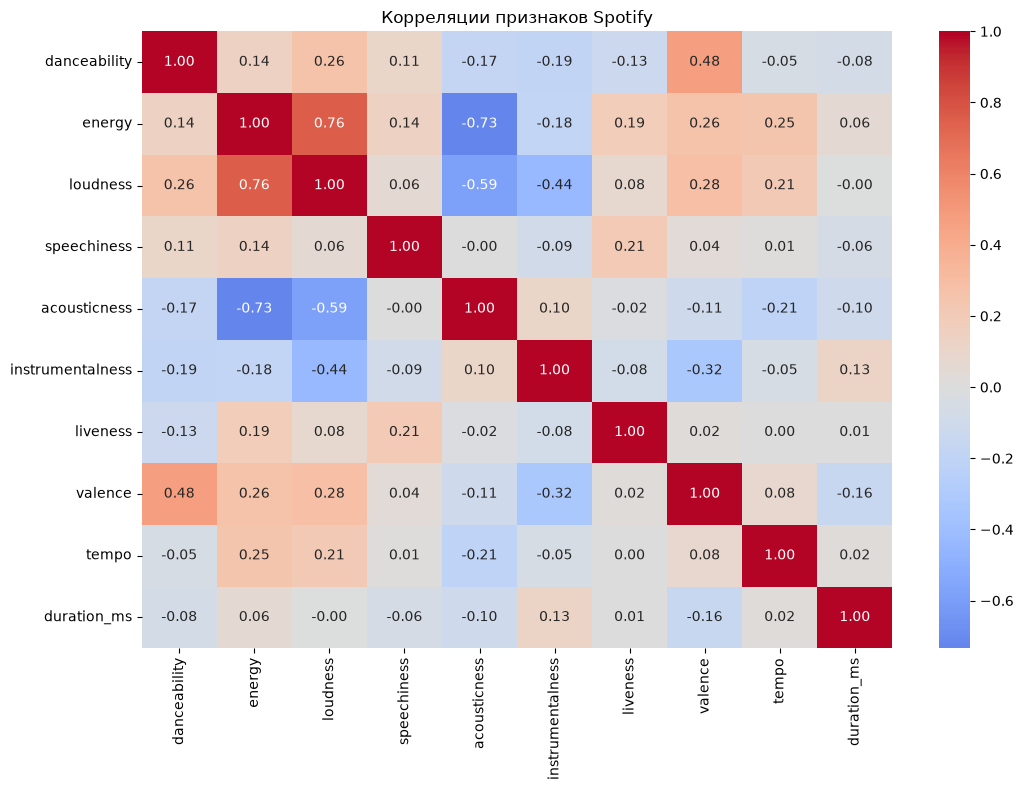

In [6]:
corr = X_train[features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Корреляции признаков Spotify")
plt.tight_layout()
plt.show()

Проверим пары с сильной корреляцией:

In [7]:
corr_abs = corr.abs()

upper = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

strong_pairs = upper.stack()
strong_pairs = strong_pairs[strong_pairs > 0.8]

print("Пары с корреляцией выше 0.8:")
print(strong_pairs.sort_values(ascending=False))

Пары с корреляцией выше 0.8:
Series([], dtype: float64)


Ячейка 7. Сокращённый набор признаков

In [8]:
to_remove = set()

for feature_a, feature_b in strong_pairs.index:
    if feature_a not in to_remove:
        to_remove.add(feature_b)

reduced_features = [
    feature for feature in features
    if feature not in to_remove
]

print("Удалённые признаки:", sorted(to_remove))
print("Оставшиеся признаки:", reduced_features)

Удалённые признаки: []
Оставшиеся признаки: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']


Ячейка 8. Обучение второй модели

reduced_model = make_model(reduced_features)

reduced_model.fit(
    X_train[reduced_features],
    y_train
)

reduced_pred = reduced_model.predict(
    X_test[reduced_features]
)

reduced_metrics = evaluate(y_test, reduced_pred)

results = pd.DataFrame(
    [baseline_metrics, reduced_metrics],
    index=["Все признаки", "Сокращённый набор"]
)

display(results.round(4))

Ячейка 9. График предсказаний

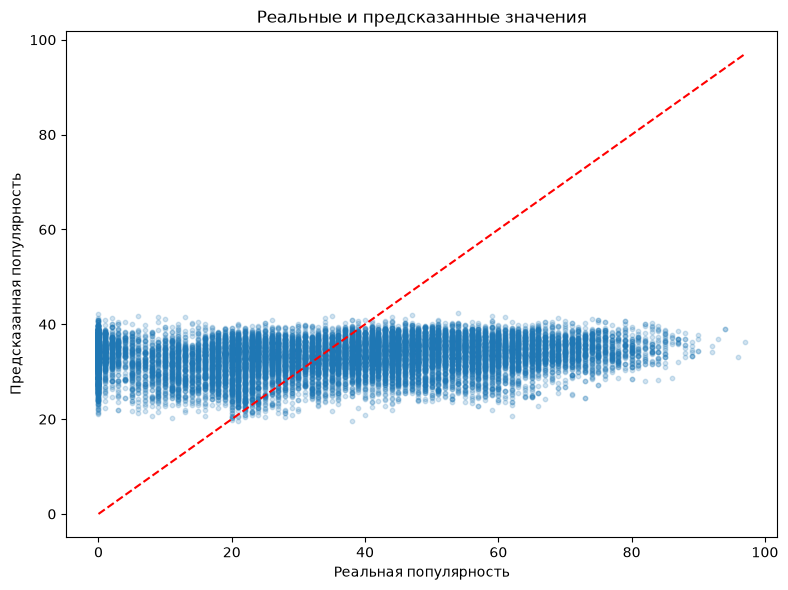

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    baseline_pred,
    alpha=0.2,
    s=10
)

limits = [
    min(y_test.min(), baseline_pred.min()),
    max(y_test.max(), baseline_pred.max())
]

plt.plot(limits, limits, "r--")

plt.xlabel("Реальная популярность")
plt.ylabel("Предсказанная популярность")
plt.title("Реальные и предсказанные значения")
plt.tight_layout()
plt.show()

Ячейка 10. Анализ остатков

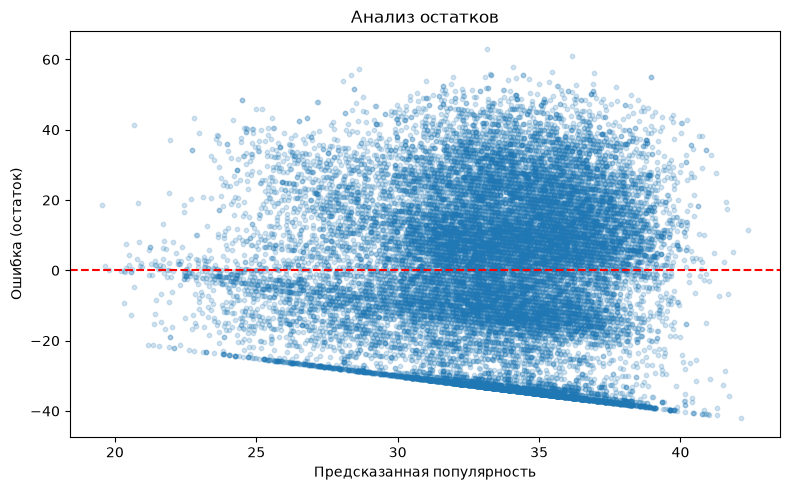

In [10]:
residuals = y_test - baseline_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    baseline_pred,
    residuals,
    alpha=0.2,
    s=10
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Предсказанная популярность")
plt.ylabel("Ошибка (остаток)")
plt.title("Анализ остатков")
plt.tight_layout()
plt.show()

Ячейка 11. Коэффициенты модели

In [11]:
coefficients = pd.Series(
    baseline.named_steps["model"].coef_,
    index=features
)

print("Коэффициенты модели:")
display(coefficients.sort_values(key=abs, ascending=False))

print("Средняя абсолютная ошибка:")
print(round(baseline_metrics["MAE"], 2))

Коэффициенты модели:


valence            -2.572852
instrumentalness   -2.558348
danceability        1.594169
speechiness        -1.307423
energy             -0.750057
loudness            0.570033
acousticness       -0.487683
tempo               0.439418
liveness            0.266182
duration_ms        -0.239846
dtype: float64

Средняя абсолютная ошибка:
18.35


## Итоги работы

В этой работе я обучил линейную регрессию для предсказания популярности треков Spotify.

**Результаты модели:**
- MAE: [значение]
- RMSE: [значение]
- R²: [значение]

Я сравнил модели с разными наборами признаков и проверил ошибки предсказаний.

**Вывод:** [указать, какая модель показала лучший результат и насколько точно она предсказывает популярность].